In [ ]:
import sys
#sys.path.append('../../npl_research/')
sys.path.append('src/')
from hcp_IO import load_scaffold_schaefer300
from utils import apply_threshold_to_nested_dict, threshold_matrix
from fingerprinting import compute_group_consistency, compute_differential_power
from viz import plot_connectivity_matrix_functional_subnetworks

import pickle as pk
import numpy as np

import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder


from collections import Counter



%load_ext autoreload
%autoreload 2

## Load the data

In [10]:
sup_folder = '/data/shared/'
data_dir = sup_folder + 'HCP/100unrelated/schaefer300/no_hp/'
scaffold_dir = 'scaffolds/whole/'
fc_dir = 'fc/whole/'

#scaffolds
sc = load_scaffold_schaefer300(data_dir+scaffold_dir+'freq/')

#fc
with open(data_dir+'fc/whole/whole_corrs.pck', 'rb') as f:
    fc = pk.load(f)
fc_th = apply_threshold_to_nested_dict(fc,1)

#open list of regions from txt
subnet_list = []
with open(sup_folder + 'HCP/100unrelated/schaefer300/Schaefer2018_300Parcels_7Networks_order.lut','r') as f:
    for line in f:
        elements = line.strip().split(' ')
        subnet_list.append(elements[4].split('_')[2])

#encode subnet names as numbers
label_encoder = LabelEncoder()
subnet_num_list = label_encoder.fit_transform(subnet_list)

In [11]:
#binarize the lists of scaffolds and thresholded fc

s0 = np.array([(sub[0]>0).astype(int) for sub in sc.values()])
s1 = np.array([(sub[1]>0).astype(int) for sub in sc.values()])

fc0 = np.array([(sub[0]>0).astype(int) for sub in fc_th.values()])
fc1 = np.array([(sub[1]>0).astype(int) for sub in fc_th.values()])

In [12]:
#sum the binarized connectivity matrix, the results gives each edge a weight
# that correspond to the % of individuals that have it

s0_all = np.sum(s0,axis=0)
s1_all = np.sum(s1,axis=0)

fc0_all = np.sum(fc0,axis=0)
fc1_all = np.sum(fc1,axis=0)

In [14]:
#open list of regions from txt
subnet_list = []
with open(sup_folder + 'HCP/100unrelated/schaefer300/Schaefer2018_300Parcels_7Networks_order.lut','r') as f:
    for line in f:
        elements = line.strip().split(' ')
        subnet_list.append(elements[4].split('_')[2])

#encode subnet names as numbers
label_encoder = LabelEncoder()
subnet_num_list = label_encoder.fit_transform(subnet_list)


subnet_dict = dict(zip(label_encoder.classes_, range(0,subnet_num_list.max()+1)))


subnet_order = np.argsort(subnet_num_list, kind='stable')

counts = Counter(subnet_num_list)
ordered_counts = dict(sorted(counts.items()))
num_roi_per_subnet = [counts[i] for i in ordered_counts.keys()]
subnet_ranges = []
start_idx = 0
for lenght in num_roi_per_subnet:
    subnet_ranges.append((start_idx, start_idx+lenght))
    start_idx += lenght

from matplotlib.colors import ListedColormap
import palettable as pltt

colors = [ListedColormap(pltt.colorbrewer.qualitative.Set2_7.mpl_colors)(i) for i in range(0,7)]

<Axes: >

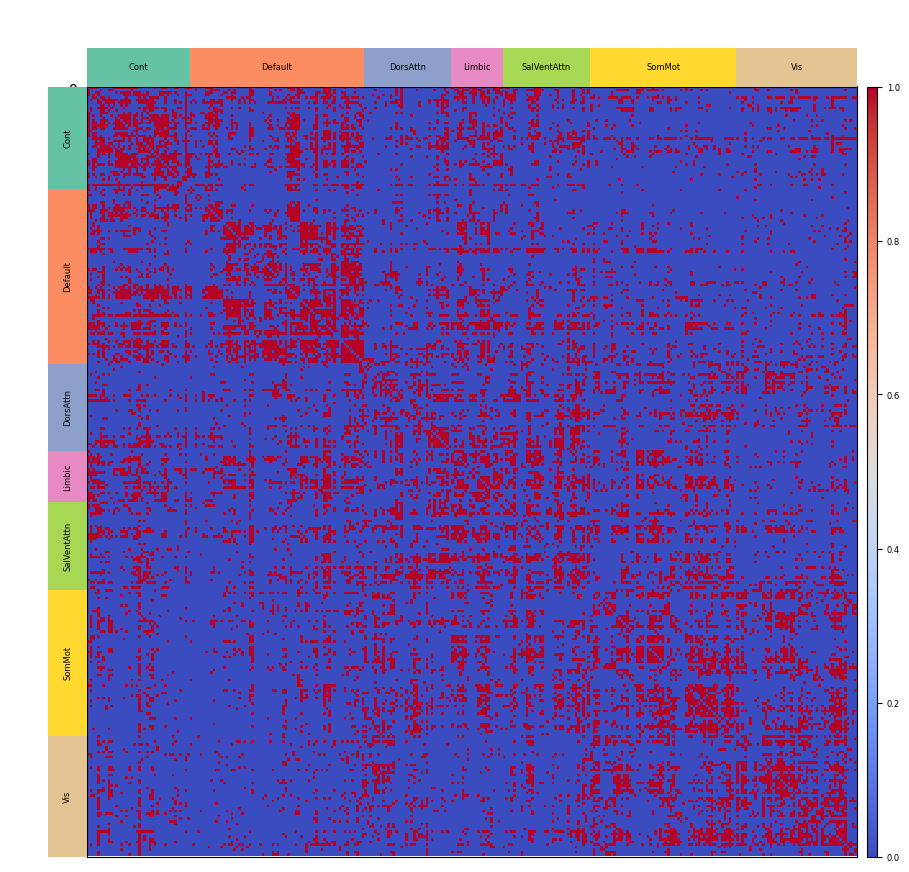

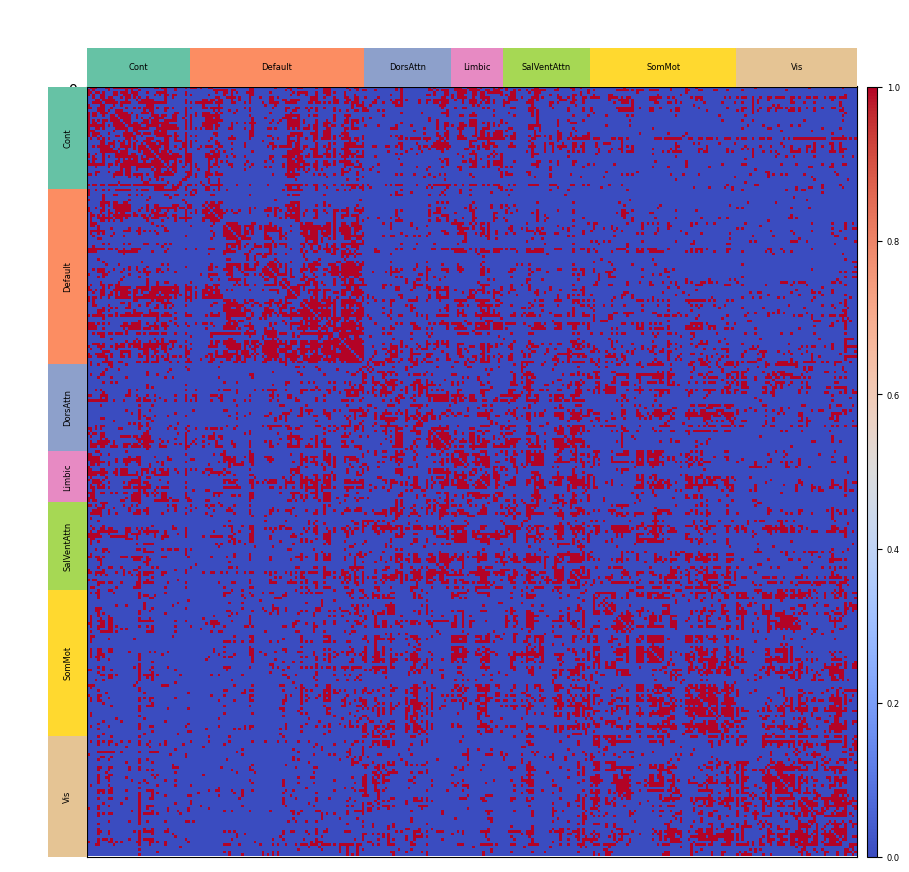

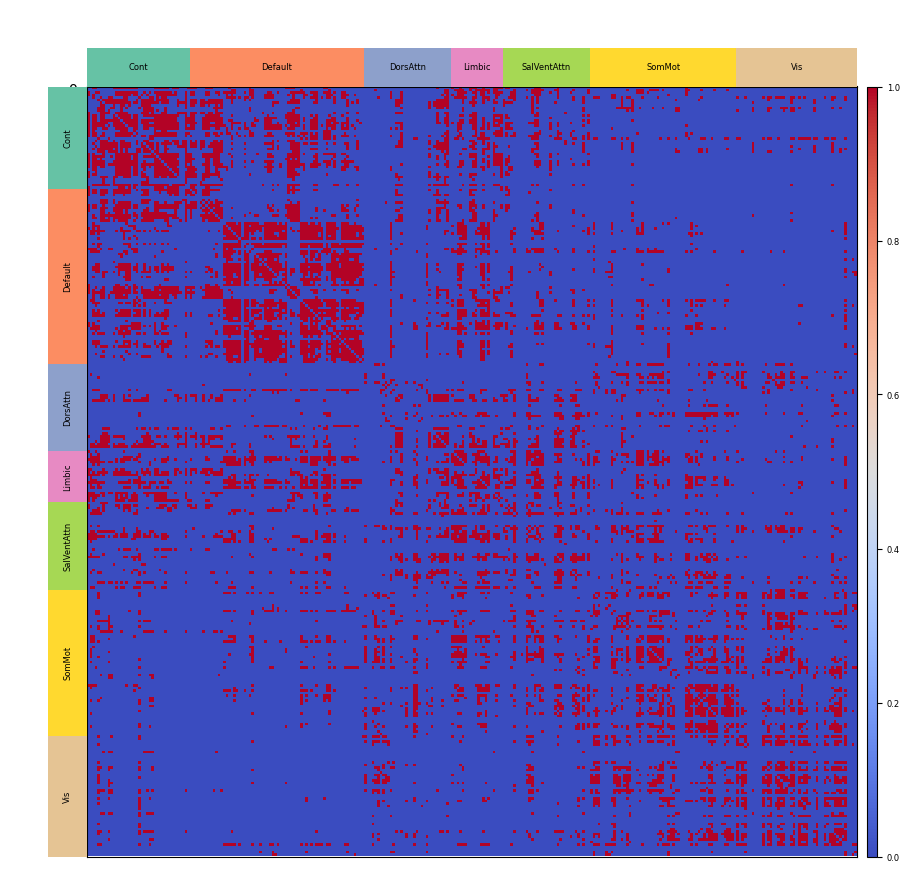

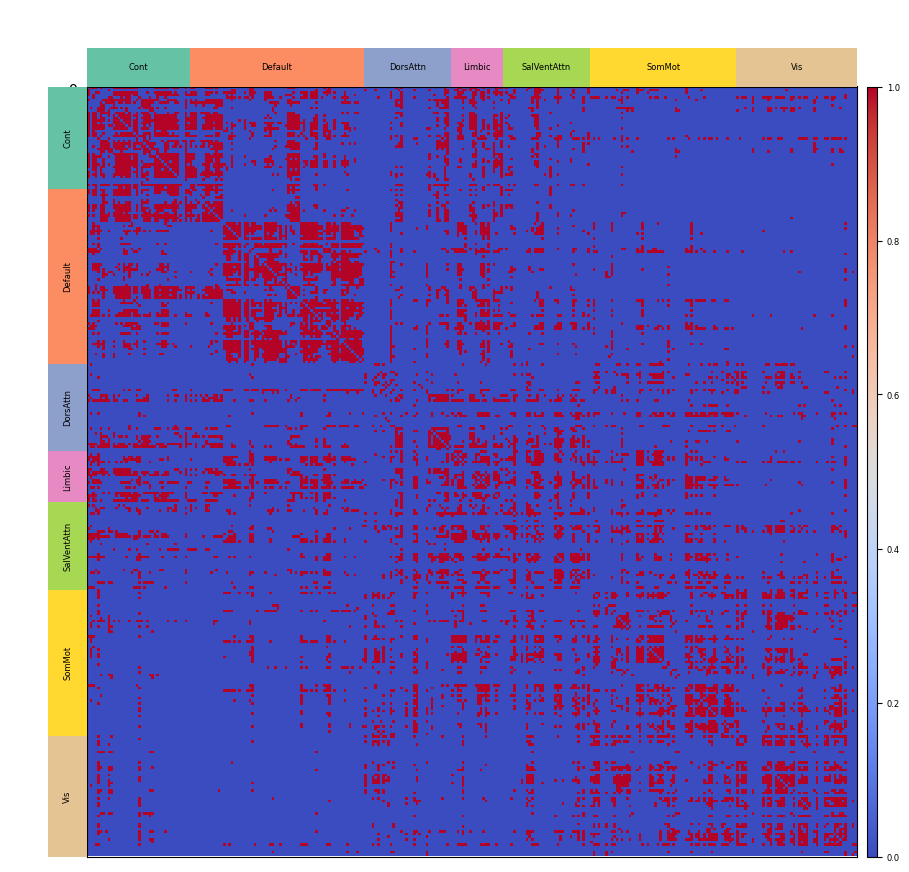

In [15]:
s0_all[s0_all!=0] = 1
s1_all[s1_all!=0] = 1
fc0_all[fc0_all!=0] = 1
fc1_all[fc1_all!=0] = 1


plot_connectivity_matrix_functional_subnetworks(s0_all, subnet_dict.keys(), subnet_order, colors, subnet_ranges)
plot_connectivity_matrix_functional_subnetworks(s1_all, subnet_dict.keys(), subnet_order, colors, subnet_ranges)

plot_connectivity_matrix_functional_subnetworks(fc0_all, subnet_dict.keys(), subnet_order, colors, subnet_ranges)
plot_connectivity_matrix_functional_subnetworks(fc1_all, subnet_dict.keys(), subnet_order, colors, subnet_ranges)


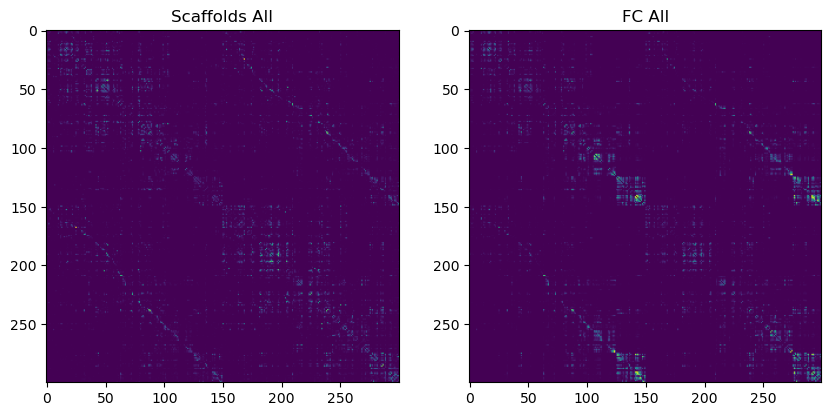

In [16]:
s0 = np.array([sub[0] for sub in sc.values()])
s1 = np.array([sub[1] for sub in sc.values()])

scaffolds_all = np.sum(np.concatenate((s0, s1), axis=0), axis=0)
#scaffolds_all = (scaffolds_all > 100).astype(int)

fc0 = np.array([sub[0] for sub in fc_th.values()])
fc1 = np.array([sub[1] for sub in fc_th.values()])

fc_all = np.sum(np.concatenate((fc0, fc1), axis=0), axis=0)
#fc_all = (fc_all > 50).astype(int)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(scaffolds_all, cmap='viridis')
axs[0].set_title('Scaffolds All')
axs[1].imshow(fc_all, cmap='viridis')
axs[1].set_title('FC All')
plt.show()

In [28]:
#open list of regions from txt
subnet_list = []
with open(sup_folder + 'HCP/100unrelated/schaefer300/Schaefer2018_300Parcels_7Networks_order.lut','r') as f:
    for line in f:
        elements = line.strip().split(' ')
        subnet_list.append(elements[4].split('_')[2])

#encode subnet names as numbers
label_encoder = LabelEncoder()
subnet_num_list = label_encoder.fit_transform(subnet_list)


subnet_dict = dict(zip(label_encoder.classes_, range(0,subnet_num_list.max()+1)))


subnet_order = np.argsort(subnet_num_list, kind='stable')

counts = Counter(subnet_num_list)
ordered_counts = dict(sorted(counts.items()))
num_roi_per_subnet = [counts[i] for i in ordered_counts.keys()]
subnet_ranges = []
start_idx = 0
for lenght in num_roi_per_subnet:
    subnet_ranges.append((start_idx, start_idx+lenght))
    start_idx += lenght

from matplotlib.colors import ListedColormap
import palettable as pltt

colors = [ListedColormap(pltt.colorbrewer.qualitative.Set2_7.mpl_colors)(i) for i in range(0,7)]

<Axes: >

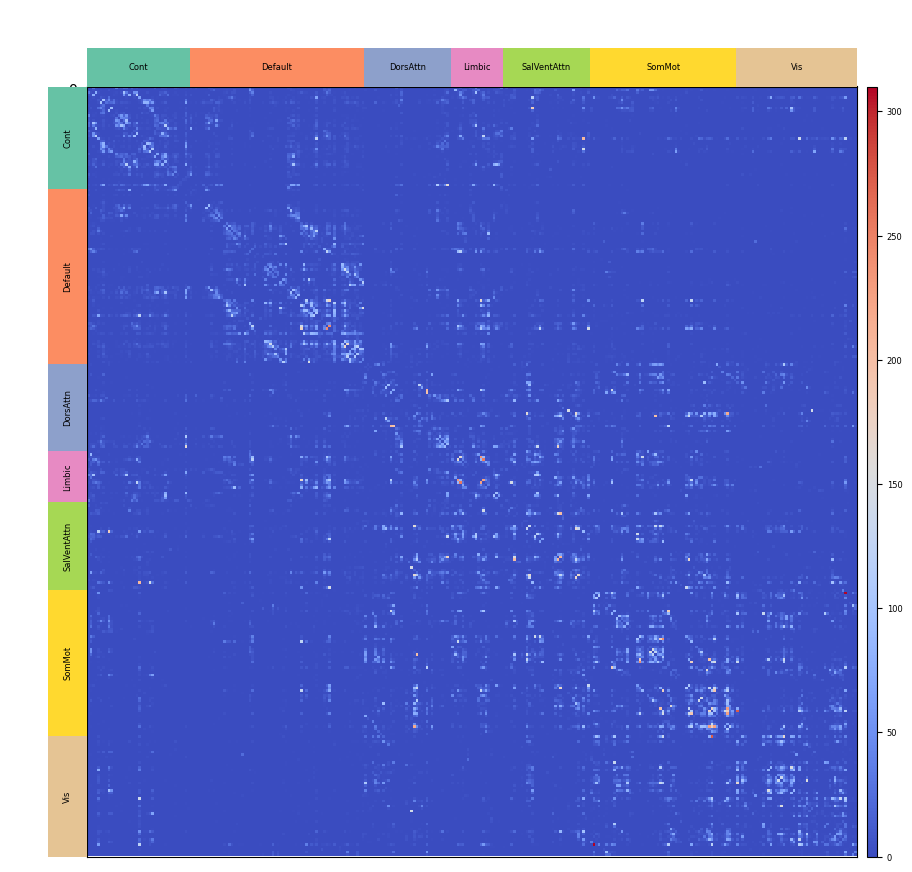

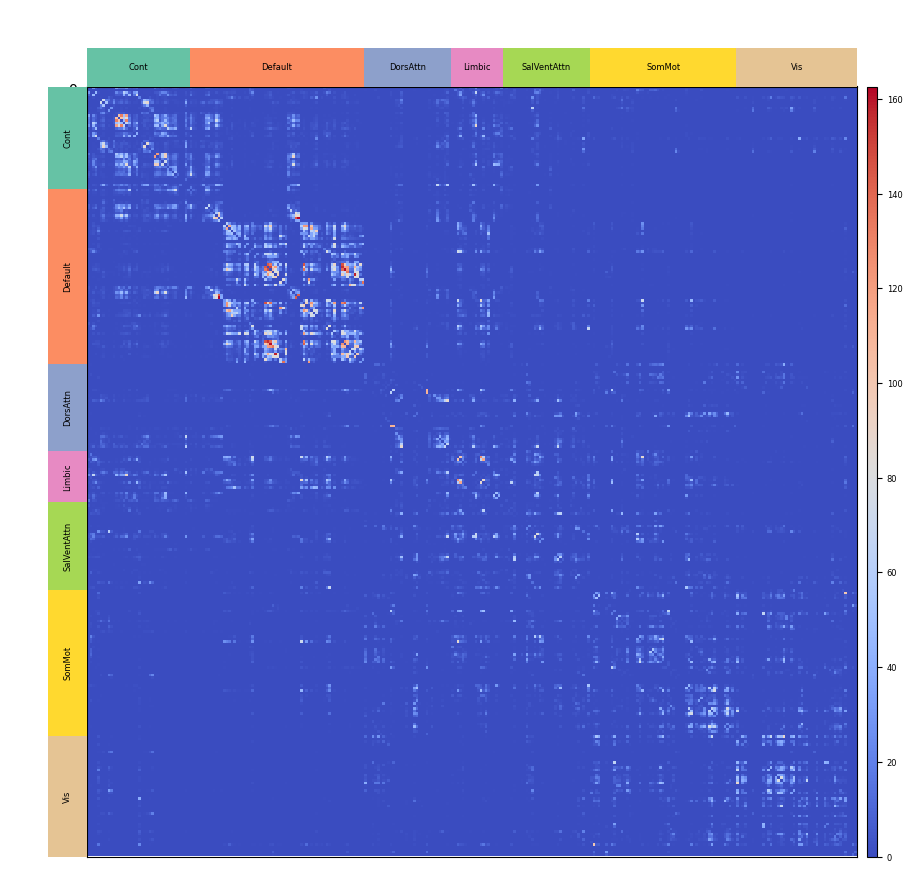

In [18]:
plot_connectivity_matrix_functional_subnetworks(scaffolds_all, subnet_dict.keys(), subnet_order, colors, subnet_ranges)
plot_connectivity_matrix_functional_subnetworks(fc_all, subnet_dict.keys(), subnet_order, colors, subnet_ranges)

## Group consistency

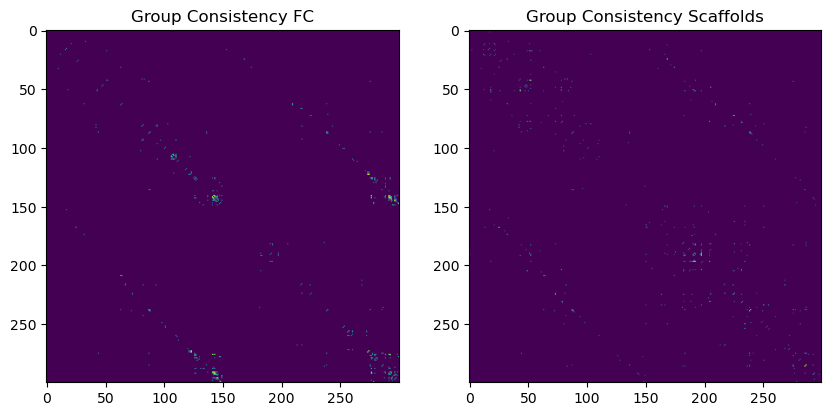

In [19]:
group_consistency_fc = compute_group_consistency(fc_th, z=True)
group_consistency_sc = compute_group_consistency(sc, z=True)


fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# Plot group consistency of FC
axs[0].imshow(threshold_matrix(group_consistency_fc, 0.5))
axs[0].set_title('Group Consistency FC')

# Plot group consistency of SC
axs[1].imshow(threshold_matrix(group_consistency_sc, 0.5))
axs[1].set_title('Group Consistency Scaffolds')

plt.show()

For the group consistency the z score doesn't change results
If we compute the mean value instead of the density in each area we see a more spread distribution of scaffolds links across regions

## Differential power

In [22]:
differential_power_fc = compute_differential_power(fc_th, z=True)
differential_power_sc = compute_differential_power(sc, z=True)

/data/shared/spoetto/projects/topological-fingerprinting/src/fingerprinting.py:99: RuntimeWarning: divide by zero encountered in log
  differential_power = -np.log(np.array(subject_DP)).sum(axis=0)
/data/shared/spoetto/projects/topological-fingerprinting/src/fingerprinting.py:99: RuntimeWarning: divide by zero encountered in log
  differential_power = -np.log(np.array(subject_DP)).sum(axis=0)


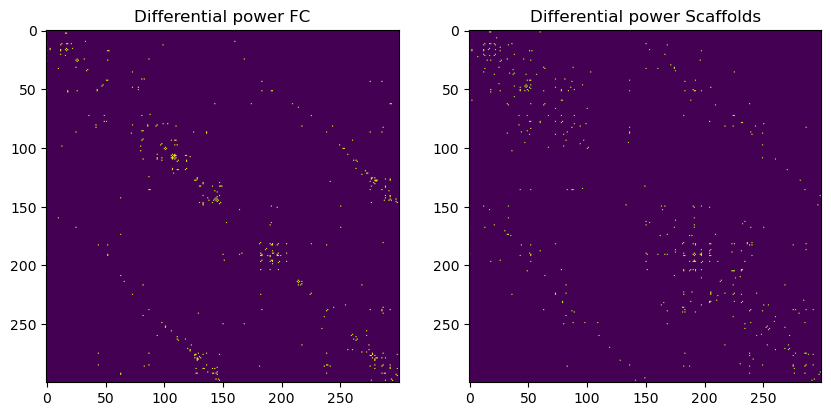

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# Plot group consistency of FC
axs[0].imshow(threshold_matrix(differential_power_fc, 0.5))
axs[0].set_title('Differential power FC')

# Plot group consistency of SC
axs[1].imshow(threshold_matrix(differential_power_sc, 0.5))
axs[1].set_title('Differential power Scaffolds')

plt.show()

In [27]:
edge_importance_all = {
    "differential_power_fc": differential_power_fc,
    "differential_power_sc": differential_power_sc,
    "group_consistency_fc": group_consistency_fc,
    "group_consistency_sc": group_consistency_sc
}

with open('results/edge_importance_all.pck', 'wb') as f:
    pk.dump(edge_importance_all, f)